# Visualisasi Usia Penumpang Titanic berdasarkan Status Keselamatan
Alur: **Pengecekan data asli vs median → Visualisasi → EDA**

## 1. Import library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

sns.set_theme(style="whitegrid")
WARNA = {"Tidak Selamat": "#d95f5f", "Selamat": "#4c9f70"}

## 2. Pengecekan data asli vs median
Data yang dipakai sudah bersih (`TITANIC_CLEAN.csv`). Usia yang kosong pada data asli sudah diisi dengan median, jadi di sini dicek perbedaan keduanya.

### 2.1 Baca data asli dan data bersih

In [2]:
drive.mount('/content/drive')

folder = '/content/drive/MyDrive/TUGAS ADIT/Smt 5/DATA MINING/TUGAS2/'
df_asli = pd.read_csv(folder + 'Titanic-Dataset.csv')   # data asli (usia masih ada yang kosong)
df = pd.read_csv(folder + 'TITANIC_CLEAN.csv')          # data bersih (usia kosong sudah diisi median)

print("Ukuran data asli  :", df_asli.shape)
print("Ukuran data bersih:", df.shape)

Mounted at /content/drive
Ukuran data asli  : (891, 12)
Ukuran data bersih: (891, 12)


### 2.2 Usia kosong pada data asli dan median pengisinya

In [3]:
kosong_asli = df_asli["Age"].isna().sum()
median_asli = df_asli["Age"].median()

print(f"Usia kosong di data asli  : {kosong_asli} dari {len(df_asli)} ({kosong_asli/len(df_asli)*100:.0f}%)")
print("Usia kosong di data bersih:", df["Age"].isna().sum())
print("Median usia data asli     :", median_asli)

# Penanda usia yang kosong pada data asli (dicocokkan lewat PassengerId)
usia_asli = df["PassengerId"].map(df_asli.set_index("PassengerId")["Age"])
df["Age_kosong"] = usia_asli.isna()

# Apakah usia yang kosong benar-benar diisi median, dan usia lainnya tidak berubah?
print("Nilai usia pada baris yang kosong :", df.loc[df["Age_kosong"], "Age"].unique())
print("Usia asli tetap sama              :", (df.loc[~df["Age_kosong"], "Age"] == usia_asli[~df["Age_kosong"]]).all())

Usia kosong di data asli  : 177 dari 891 (20%)
Usia kosong di data bersih: 0
Median usia data asli     : 28.0
Nilai usia pada baris yang kosong : [28.]
Usia asli tetap sama              : True


### 2.3 Perbandingan statistik usia: data asli vs data bersih

In [4]:
perbandingan = pd.DataFrame({
    "Data asli": df_asli["Age"].describe(),
    "Data bersih (diisi median)": df["Age"].describe()
}).round(1)
display(perbandingan)

,Data asli,Data bersih (diisi median)
count,714.0,891.0
mean,29.7,29.4
std,14.5,13.0
min,0.4,0.4
25%,20.1,22.0
50%,28.0,28.0
75%,38.0,35.0
max,80.0,80.0


## 3. Persiapan untuk visualisasi

In [5]:
df["Status"] = df["Survived"].map({0: "Tidak Selamat", 1: "Selamat"})

batas = [0, 10, 20, 30, 40, 50, 60, 70]
label = ["0-10", "11-20", "21-30", "31-40", "41-50", "51-60", "61-70"]
df["Rentang_Usia"] = pd.cut(df["Age"], bins=batas, labels=label, include_lowest=True)

median_usia = df["Age"].median()
df["Sumber_Usia"] = df["Age_kosong"].map({False: "Usia asli", True: f"Diisi median ({median_usia})"})

## 4. Visualisasi

### 4.1 Usia asli vs usia yang diisi median

177 dari 891 usia kosong (20%), diisi median = 28.0


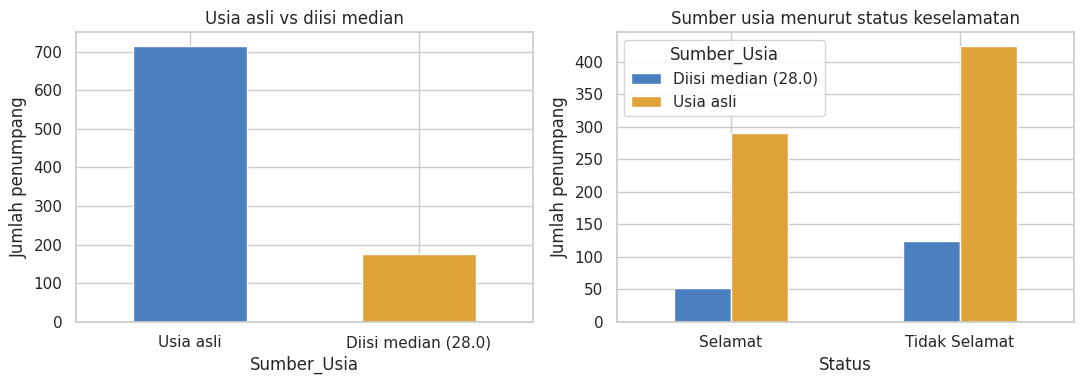

In [6]:
n_kosong = df["Age_kosong"].sum()
print(f"{n_kosong} dari {len(df)} usia kosong ({n_kosong/len(df)*100:.0f}%), diisi median = {median_usia}")

warna = ["#4c7fbf", "#e0a33a"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

df["Sumber_Usia"].value_counts().plot.bar(ax=ax[0], color=warna, rot=0)
ax[0].set_title("Usia asli vs diisi median")
ax[0].set_ylabel("Jumlah penumpang")

pd.crosstab(df["Status"], df["Sumber_Usia"]).plot.bar(ax=ax[1], color=warna, rot=0)
ax[1].set_title("Sumber usia menurut status keselamatan")
ax[1].set_ylabel("Jumlah penumpang")
plt.tight_layout(); plt.show()

### 4.2 Jumlah penumpang per rentang usia, Selamat vs Tidak Selamat

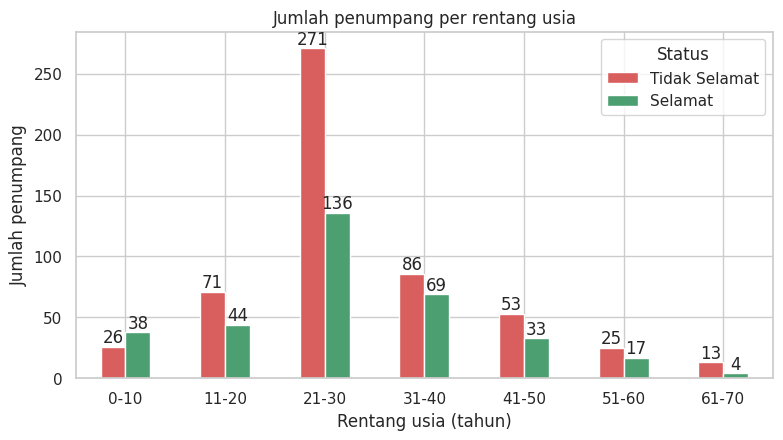

In [7]:
tabel = pd.crosstab(df["Rentang_Usia"], df["Status"])[["Tidak Selamat", "Selamat"]]

ax = tabel.plot.bar(figsize=(9, 4.5), color=[WARNA["Tidak Selamat"], WARNA["Selamat"]], rot=0)
ax.set_title("Jumlah penumpang per rentang usia")
ax.set_xlabel("Rentang usia (tahun)")
ax.set_ylabel("Jumlah penumpang")
for c in ax.containers:
    ax.bar_label(c)
plt.show()

### 4.3 Histogram dan boxplot usia

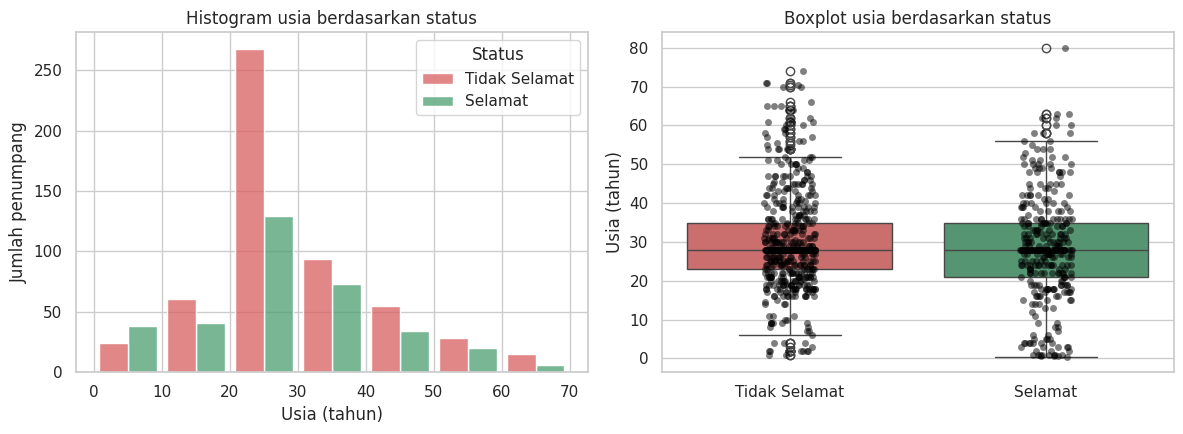

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

sns.histplot(data=df, x="Age", hue="Status", bins=range(0, 80, 10),
             palette=WARNA, multiple="dodge", shrink=0.85, ax=ax[0])
ax[0].set_title("Histogram usia berdasarkan status")
ax[0].set_xlabel("Usia (tahun)")
ax[0].set_ylabel("Jumlah penumpang")

sns.boxplot(data=df, x="Status", y="Age", order=["Tidak Selamat", "Selamat"],
            hue="Status", palette=WARNA, legend=False, ax=ax[1])
sns.stripplot(data=df, x="Status", y="Age", order=["Tidak Selamat", "Selamat"],
              color="black", alpha=0.5, ax=ax[1])
ax[1].set_title("Boxplot usia berdasarkan status")
ax[1].set_xlabel("")
ax[1].set_ylabel("Usia (tahun)")
plt.tight_layout(); plt.show()

## 5. EDA

### 5.1 Statistik usia per status

In [9]:
df.groupby("Status")["Age"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Status,,,,,,,,
Selamat,342.0,28.3,13.8,0.4,21.0,28.0,35.0,80.0
Tidak Selamat,549.0,30.0,12.5,1.0,23.0,28.0,35.0,74.0


### 5.2 Tingkat keselamatan per rentang usia

,jumlah,selamat,tingkat_selamat
Rentang_Usia,,,
0-10,64,38,59.4
11-20,115,44,38.3
21-30,407,136,33.4
31-40,155,69,44.5
41-50,86,33,38.4
51-60,42,17,40.5
61-70,17,4,23.5


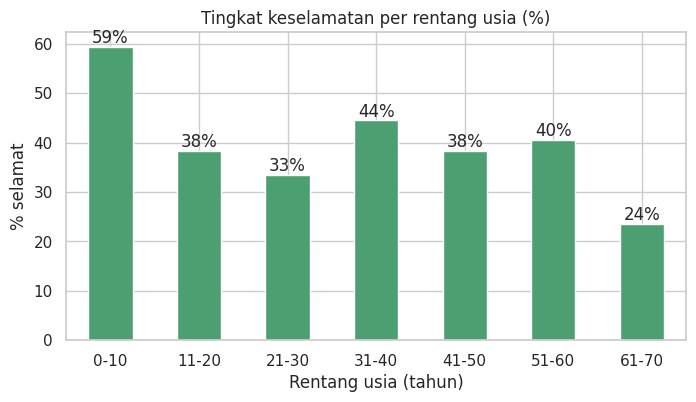

In [10]:
eda = df.groupby("Rentang_Usia", observed=True).agg(
    jumlah=("Survived", "size"),
    selamat=("Survived", "sum"),
    tingkat_selamat=("Survived", "mean"),
)
eda["tingkat_selamat"] = (eda["tingkat_selamat"] * 100).round(1)
display(eda)

ax = eda["tingkat_selamat"].plot.bar(figsize=(8, 4), color="#4c9f70", rot=0)
ax.set_title("Tingkat keselamatan per rentang usia (%)")
ax.set_xlabel("Rentang usia (tahun)")
ax.set_ylabel("% selamat")
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%")
plt.show()

### 5.3 Usia asli vs usia diisi median

In [11]:
kosong = df.groupby("Sumber_Usia")["Survived"].agg(["size", "mean"])
kosong["mean"] = (kosong["mean"] * 100).round(1)
kosong.columns = ["jumlah", "% selamat"]
display(kosong)

asli = df.loc[~df["Age_kosong"], "Age"]
print("Rata-rata usia asli      :", round(asli.mean(), 1), "| Std:", round(asli.std(), 1))
print("Rata-rata usia sesudah isi:", round(df["Age"].mean(), 1), "| Std:", round(df["Age"].std(), 1))

,jumlah,% selamat
Sumber_Usia,,
Diisi median (28.0),177,29.4
Usia asli,714,40.6


Rata-rata usia asli      : 29.7 | Std: 14.5
Rata-rata usia sesudah isi: 29.4 | Std: 13.0


### 5.4 Jumlah penumpang menurut jenis kelamin dan status

In [12]:
pd.crosstab(df["Sex"], df["Status"])

Status,Selamat,Tidak Selamat
Sex,,
female,233,81
male,109,468
